# 09_07 How Language Models Sample: Temperature, Top-k, Top-p and the Gumbel Trick

**Learning objectives**
- Write the **softmax with temperature**, derive its limits ($T\to0$: argmax, $T\to\infty$: uniform) and compute the **entropy** of the next-token distribution as a function of $T$.
- Implement **greedy, temperature, top-$k$, top-$p$ (nucleus) and min-$p$ sampling** and explain how truncation **renormalises** the distribution and what it costs in KL divergence.
- Prove the **Gumbel-max trick** ($\arg\max(\text{logits}+\text{Gumbel noise})$ is an exact categorical sample) and use the **Gumbel-softmax** relaxation for differentiable sampling.
- Measure quality and diversity of generated text (**perplexity, distinct-$n$, repetition**) on a real corpus, using a word-level **bigram language model** trained on the SMS Spam Collection, and calibrate the temperature on held-out data.

**Prerequisites:** [08_01 Entropy and cross-entropy](../../module_08_information/notebooks/08_01_entropy_cross_entropy.ipynb), [08_02 KL divergence](../../module_08_information/notebooks/08_02_kl_js_divergence.ipynb), [01_06 Multinomial](../../module_01_discrete/notebooks/01_06_multinomial.ipynb), [09_03 Naive Bayes](09_03_naive_bayes.ipynb) (the SMS data).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
A language model gives a probability distribution over the next token $x_t$ given the previous ones: $p(x_t\mid x_{<t})$. A text of $n$ tokens has probability $\prod_tp(x_t\mid x_{<t})$ and **perplexity** $\exp\{-\frac1n\sum\ln p(x_t\mid x_{<t})\}$, the exponential of the cross-entropy (08_01). The softmax turns scores (logits) $z_j$ into probabilities $p_j=e^{z_j}/\sum_ke^{z_k}$. The Gumbel distribution has CDF $e^{-e^{-g}}$.

## 3. Intuition and story
A language model does not output a word; it outputs **a probability for every word** in its vocabulary. Producing text means *drawing* from that distribution, again and again. Two extremes: always taking the most likely word (greedy) gives bland, repetitive text; drawing exactly from the model's distribution gives diverse but sometimes incoherent text, because the long tail of unlikely words has a lot of total probability. The decoding settings (**temperature**, **top-$k$**, **top-$p$**) reshape the distribution before drawing: temperature sharpens or flattens it; truncation cuts off the tail and renormalises. All of them are small, exactly computable operations on one probability vector, which is why they can be studied as statistics.

## 4. Formal definitions

For logits $z\in\mathbb R^V$ and temperature $T>0$: $\ p_j^{(T)}=\dfrac{e^{z_j/T}}{\sum_ke^{z_k/T}}$.

| Method | Rule | Parameters |
|---|---|---|
| **Greedy** | $\arg\max_jp_j$ | none |
| **Temperature** | sample from $p^{(T)}$ | $T$ |
| **Top-$k$** | keep the $k$ most likely tokens, renormalise | $k$ |
| **Top-$p$ (nucleus)** | keep the smallest set $S$ of top tokens with $\sum_{j\in S}p_j\ge p$, renormalise | $p$ |
| **Min-$p$** | keep tokens with $p_j\ge\rho\max_kp_k$, renormalise | $\rho$ |
| **Gumbel-max** | $j=\arg\max_k(z_k+G_k)$, $G_k\sim\mathrm{Gumbel}(0,1)$ i.i.d. | none |
| **Gumbel-softmax** | $y_j=\dfrac{e^{(z_j+G_j)/\tau}}{\sum_ke^{(z_k+G_k)/\tau}}$ | $\tau$ |

**Truncation cost.** If the kept set has probability mass $m=\sum_{j\in S}p_j$ and $q=p_S/m$ is the renormalised distribution, then $\mathrm{KL}(q\|p)=-\ln m$. **Entropy:** $H(p^{(T)})=-\sum p_j^{(T)}\ln p_j^{(T)}$, increasing in $T$ from 0 to $\ln V$.

## 5. Derivations

### 5.1 Temperature and its limits
Divide the logits by $T$: $\ln p^{(T)}_j=z_j/T-\ln\sum_ke^{z_k/T}$. As $T\to0$ the largest logit dominates: $p^{(T)}\to$ one-hot at the argmax (greedy); as $T\to\infty$ all $z_j/T\to0$ and $p^{(T)}\to1/V$ (uniform). For two tokens with logit gap $\Delta$ the probability ratio is $e^{\Delta/T}$. **In plain words.** Temperature is a confidence knob: halving $T$ squares the odds between any two words, doubling it takes their square root.

### 5.2 The entropy is increasing in $T$
$\dfrac{dH}{dT}=\dfrac{\mathrm{Var}_{p^{(T)}}(z)}{T^3}\ge0$ with equality only for equal logits (differentiate $H=\ln Z(T)+E[z]/T$ and use $d\ln Z/d(1/T)=E[z]$). **In plain words.** Raising the temperature can only make the next word less predictable, and the effect is largest when the logits differ a lot.

### 5.3 Truncation renormalises and costs $-\ln m$
After keeping a set $S$ of mass $m$ the new probabilities are $q_j=p_j/m$ on $S$ and 0 elsewhere. Then $\mathrm{KL}(q\|p)=\sum_{j\in S}\frac{p_j}m\ln\frac{p_j/m}{p_j}=-\ln m$. **In plain words.** Cutting off a tail with 5 % of the probability costs only $-\ln0.95=0.051$ nats, so top-$p$ with $p=0.95$ discards the unreliable tail almost for free; but the rest of the text is then slightly more confident than the model claims.

### 5.4 The Gumbel-max trick is exact
$G_k=-\ln(-\ln U_k)$ with $U_k\sim\mathrm{Uniform}(0,1)$. Then $P(\arg\max_k(z_k+G_k)=j)=\int f_{G}(g)\prod_{k\neq j}F_G(g+z_j-z_k)\,dg=\dfrac{e^{z_j}}{\sum_ke^{z_k}}$, using $F_G(x)=e^{-e^{-x}}$: the product becomes $\exp\{-e^{-g}\sum_{k\ne j}e^{z_k-z_j}\}$ and the integral is $\dfrac{1}{1+\sum_{k\ne j}e^{z_k-z_j}}$. **In plain words.** Add independent Gumbel noise to the logits and take the argmax: the winner is drawn exactly with the softmax probabilities, and the randomness has been moved into a noise term that does not depend on the parameters.

### 5.5 Gumbel-softmax: a differentiable relaxation
Replacing the argmax by a softmax with temperature $\tau$ gives a point on the simplex that is differentiable in the logits; as $\tau\to0$ it becomes the one-hot Gumbel-max sample. It is used to backpropagate through a discrete choice (reparameterisation, 09_08), at the price of a bias for $\tau>0$. **In plain words.** A hard choice has no gradient; a soft choice that is almost hard does, and the temperature trades the sharpness of the choice against the variance and bias of the gradient.

### 5.6 Calibrating the temperature
Given held-out tokens the negative log-likelihood of the temperature-scaled model $\mathrm{NLL}(T)=-\sum\ln p^{(T)}_{x}$ is a smooth function of $T$; a count-based model fitted on little data is typically over-confident, and the best $T$ is above 1 (08_01). **In plain words.** Temperature scaling is a one-parameter fix for a model whose probabilities are too sharp.

## 6. Properties and relationships
- **Greedy decoding** maximises each step, not the whole sentence; it is deterministic and tends to loop (the same most likely word follows itself).
- **Top-$k$ uses a fixed number of tokens**, so it is too loose where the model is sure and too tight where it is unsure; **top-$p$ adapts** the number of tokens to the shape of the distribution.
- **Quality-diversity trade-off:** lower temperature or smaller $p$: higher likelihood, more repetition; higher temperature: more variety and more errors.
- **Perplexity of generated text** under the model is low for greedy/low-$T$ text and about $e^{H}$ for ancestral sampling at $T=1$.
- **Link to ML and AI:** the decoding step of every LLM (temperature, top-$p$, min-$p$ as sampler settings), **reinforcement learning from human feedback** (sampling many continuations), **reparameterised discrete latent variables** (VAE with categorical latents, 09_08) and **discrete diffusion**, beam search and speculative decoding as alternatives.

## 7. A word-level bigram language model on real text

The SMS messages are split into word tokens with a sentence start `<s>` and end `</s>`; words seen fewer than 3 times in the training part become `<unk>`. The next-word distribution given the previous word interpolates the bigram counts with the unigram distribution ($\lambda=0.85$). This is a tiny language model, but it has the same interface as a large one: a vector of probabilities over the vocabulary for each context.

In [2]:
import re
from collections import Counter
from scipy.special import softmax, logsumexp
raw = pd.read_csv("../data/SMSSpamCollection.tsv", sep="\t", header=None, names=["label", "text"], encoding="utf-8", quoting=3); sents = [["<s>"] + re.findall(r"[a-z0-9']+|[.,!?]", t.lower()) + ["</s>"] for t in raw["text"]]
g = np.random.default_rng(0); perm = g.permutation(len(sents)); ntr = int(0.9 * len(sents)); tr = [sents[i] for i in perm[:ntr]]; te = [sents[i] for i in perm[ntr:]]
cnt = Counter(w for s in tr for w in s); vocab = ["<unk>"] + sorted(w for w, c in cnt.items() if c >= 3); idx = {w: i for i, w in enumerate(vocab)}; V = len(vocab); enc = lambda s: [idx.get(w, 0) for w in s]
C = np.zeros((V, V), dtype=np.float32)
for s in tr:
    e = enc(s)
    for a, b in zip(e[:-1], e[1:]): C[a, b] += 1
uni = C.sum(axis=0) + 1; uni = uni / uni.sum(); lam = 0.85; rowsum = C.sum(axis=1, keepdims=True)
def probs(prev): r = C[prev]; n = r.sum(); return (lam * r / n + (1 - lam) * uni) if n > 0 else uni.copy()
def nll_text(sents_, T=1.0):
    tot = 0.0; n = 0
    for s in sents_:
        e = enc(s)
        for a, b in zip(e[:-1], e[1:]): p = probs(a); lg = np.log(p) / T; tot -= lg[b] - logsumexp(lg); n += 1
    return tot / n
print(f"messages {len(sents)}, train {len(tr)}, test {len(te)}, vocabulary {V}, training tokens {int(C.sum())}"); ppl = np.exp(nll_text(te[:600])); print(f"held-out perplexity of the bigram model: {ppl:.1f} (a uniform model has perplexity {V})")
p0 = probs(idx["<s>"]); top = np.argsort(-p0)[:8]; print("most likely first words:", [(vocab[i], round(float(p0[i]), 3)) for i in top]); assert abs(p0.sum() - 1) < 1e-5 and ppl < V / 5

messages 5574, train 5016, test 558, vocabulary 2800, training tokens 99471


held-out perplexity of the bigram model: 97.7 (a uniform model has perplexity 2800)
most likely first words: [('i', 0.067), ('<unk>', 0.063), ('you', 0.022), ('ok', 0.022), ('no', 0.017), ("i'm", 0.016), ('.', 0.015), ('hi', 0.015)]


## 8. 2D visuals

### 8.1 Temperature reshapes one distribution
The next-word distribution after the word "i" at three temperatures, and the entropy of the distribution against $T$. The tail of rare words gets heavier as $T$ grows.

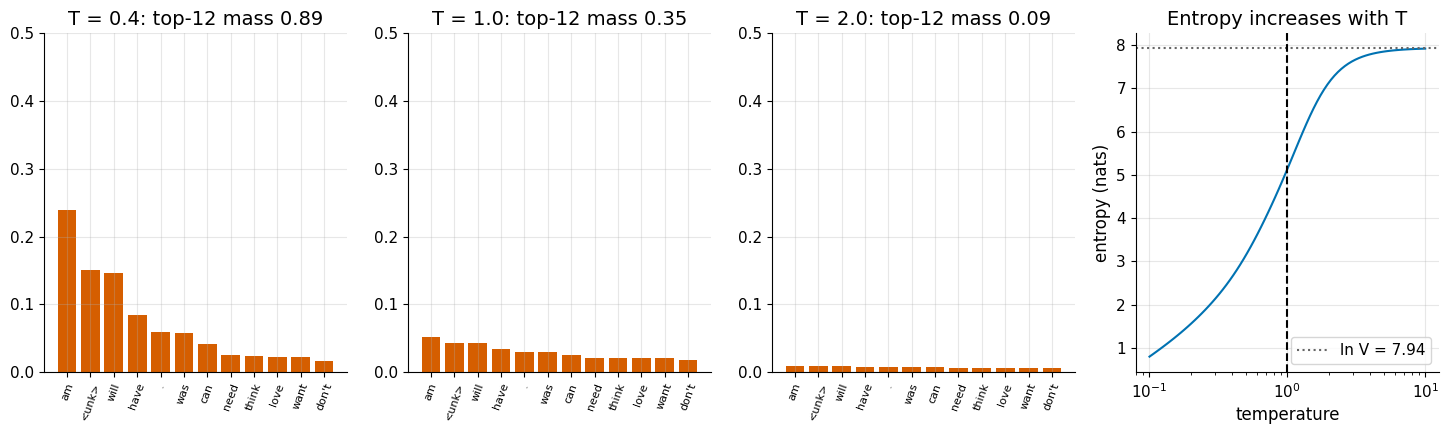

entropy at T = 0.4 / 1 / 2 / 10: [2.651, 5.133, 7.134, 7.919] | ln V = 7.937


In [3]:
ctx = idx["i"]; p = probs(ctx); z = np.log(p); order = np.argsort(-p)[:12]; fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, T_ in zip(axes[:3], [0.4, 1.0, 2.0]): q = softmax(z / T_); ax.bar(range(12), q[order], color=HIGHLIGHT); ax.set_xticks(range(12)); ax.set_xticklabels([vocab[i] for i in order], rotation=70, fontsize=8); ax.set_title(f"T = {T_}: top-12 mass {q[order].sum():.2f}"); ax.set_ylim(0, 0.5)
Ts = np.geomspace(0.1, 10, 80); H = [-(softmax(z / t) * np.log(softmax(z / t) + 1e-300)).sum() for t in Ts]; axes[3].semilogx(Ts, H, color=MAIN); axes[3].axhline(np.log(V), color=NEUTRAL, linestyle=":", label=f"ln V = {np.log(V):.2f}"); axes[3].axvline(1, color="black", linestyle="--"); axes[3].legend(); axes[3].set_xlabel("temperature"); axes[3].set_ylabel("entropy (nats)"); axes[3].set_title("Entropy increases with T")
plt.show(); print(f"entropy at T = 0.4 / 1 / 2 / 10: {[round(float(-(softmax(z / t) * np.log(softmax(z / t) + 1e-300)).sum()), 3) for t in (0.4, 1, 2, 10)]} | ln V = {np.log(V):.3f}"); assert all(np.diff(H) > -1e-9) and H[-1] < np.log(V) + 1e-9 and H[0] < 1.5

### 8.2 Where truncation cuts
The sorted probabilities after "i", the cumulative mass, and the cut-offs of top-$k$ ($k=10$), top-$p$ ($p=0.9$) and min-$p$ ($\rho=0.1$). Top-$p$ keeps few words where the model is confident and many where it is not.

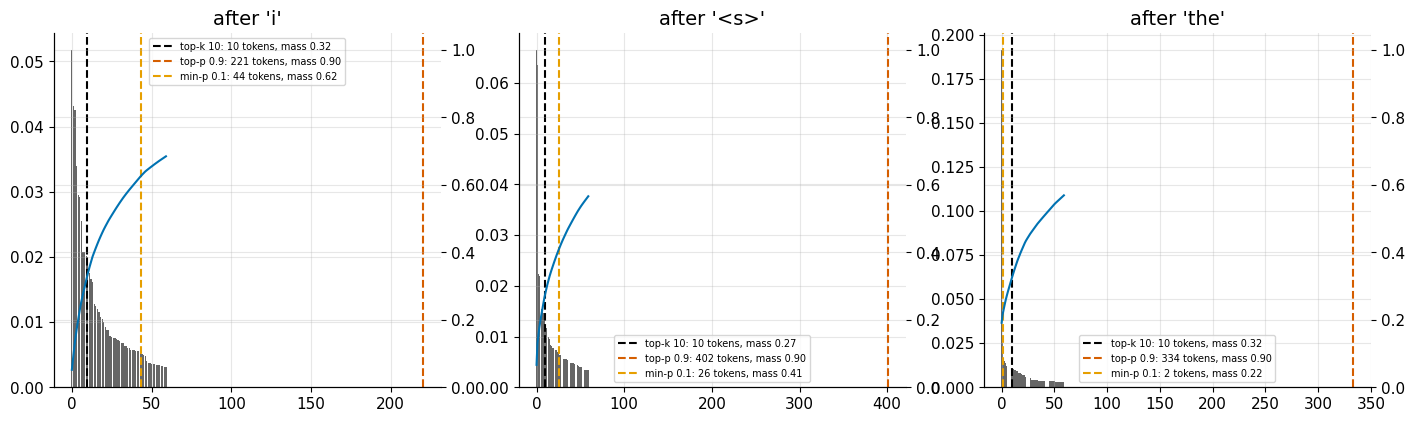

{("after 'i'", 'top-k 10'): (np.int64(10), 0.317), ("after 'i'", 'top-p 0.9'): (np.int64(221), 0.9), ("after 'i'", 'min-p 0.1'): (np.int64(44), 0.625), ("after '<s>'", 'top-k 10'): (np.int64(10), 0.266), ("after '<s>'", 'top-p 0.9'): (np.int64(402), 0.9), ("after '<s>'", 'min-p 0.1'): (np.int64(26), 0.406), ("after 'the'", 'top-k 10'): (np.int64(10), 0.317), ("after 'the'", 'top-p 0.9'): (np.int64(334), 0.9), ("after 'the'", 'min-p 0.1'): (np.int64(2), 0.216)}


In [4]:
def trunc(p, k=None, top_p=None, min_p=None):
    o = np.argsort(-p); sp = p[o]; keep = np.ones(len(p), bool)
    if k is not None: keep &= np.arange(len(p)) < k
    if top_p is not None: cs = np.cumsum(sp); keep &= (cs - sp) < top_p
    if min_p is not None: keep &= sp >= min_p * sp[0]
    q = np.zeros_like(p); q[o[keep]] = sp[keep]; return q / q.sum(), keep.sum(), sp[keep].sum()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6)); ps = {"after 'i'": probs(idx["i"]), "after '<s>'": probs(idx["<s>"]), "after 'the'": probs(idx["the"])}; sizes = {}
for ax, (nm, pp) in zip(axes, ps.items()):
    sp = np.sort(pp)[::-1][:60]; ax.bar(range(60), sp, color=NEUTRAL); ax2 = ax.twinx(); ax2.plot(np.cumsum(sp), color=MAIN); ax2.set_ylim(0, 1.05)
    for lab, kw, colr in [("top-k 10", dict(k=10), "black"), ("top-p 0.9", dict(top_p=0.9), HIGHLIGHT), ("min-p 0.1", dict(min_p=0.1), SIM)]: _, n_, m_ = trunc(pp, **kw); ax.axvline(n_ - 0.5, color=colr, linestyle="--", label=f"{lab}: {n_} tokens, mass {m_:.2f}"); sizes[(nm, lab)] = (n_, m_)
    ax.legend(fontsize=7); ax.set_title(nm)
plt.show(); print({k: (v[0], round(float(v[1]), 3)) for k, v in sizes.items()}); assert sizes[("after 'i'", "top-p 0.9")][0] != sizes[("after '<s>'", "top-p 0.9")][0] or sizes[("after 'the'", "top-p 0.9")][0] != sizes[("after 'i'", "top-p 0.9")][0]

### 8.3 The Gumbel-max trick
Left: the Gumbel(0,1) density. Right: for a 5-token distribution, the empirical frequencies of $\arg\max_k(z_k+G_k)$ over 200,000 draws against the softmax probabilities.

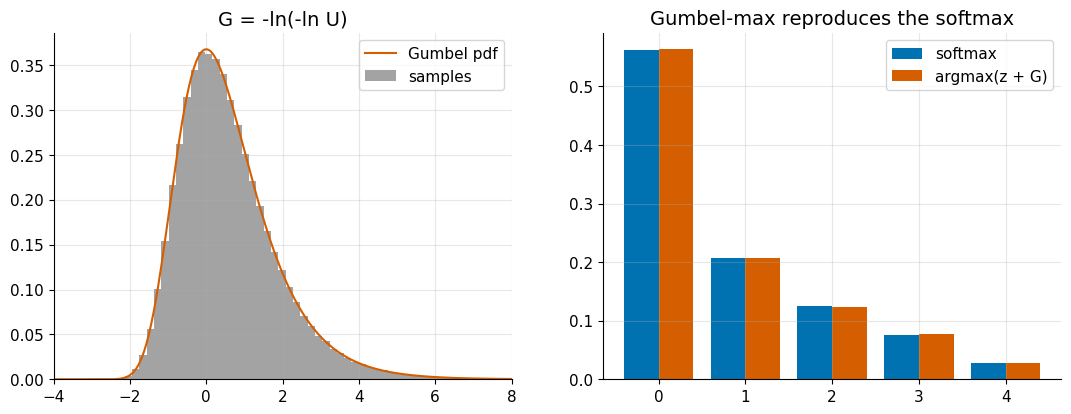

softmax: [0.563  0.2071 0.1256 0.0762 0.028 ] | Gumbel-max frequencies: [0.5634 0.207  0.1241 0.0772 0.0282] | chi-square 6.54 (4 df, 95% point 9.49), mean of G 0.5784 (Euler gamma 0.5772)


In [5]:
g = np.random.default_rng(3); zt = np.array([2.0, 1.0, 0.5, 0.0, -1.0]); pt = softmax(zt); G = -np.log(-np.log(g.random((200_000, 5)))); win = np.argmax(zt + G, axis=1); freq = np.bincount(win, minlength=5) / 200_000
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5)); xg = np.linspace(-4, 8, 400); axes[0].plot(xg, np.exp(-xg - np.exp(-xg)), color=HIGHLIGHT, label="Gumbel pdf"); axes[0].hist(G[:, 0], bins=80, density=True, color=NEUTRAL, alpha=0.6, label="samples"); axes[0].set_xlim(-4, 8); axes[0].legend(); axes[0].set_title("G = -ln(-ln U)")
axes[1].bar(np.arange(5) - 0.2, pt, 0.4, color=MAIN, label="softmax"); axes[1].bar(np.arange(5) + 0.2, freq, 0.4, color=HIGHLIGHT, label="argmax(z + G)"); axes[1].legend(); axes[1].set_title("Gumbel-max reproduces the softmax")
plt.show(); chi2 = ((np.bincount(win, minlength=5) - 200_000 * pt) ** 2 / (200_000 * pt)).sum(); print("softmax:", pt.round(4), "| Gumbel-max frequencies:", freq.round(4), f"| chi-square {chi2:.2f} (4 df, 95% point 9.49), mean of G {G.mean():.4f} (Euler gamma 0.5772)"); assert chi2 < 13.3 and abs(G.mean() - 0.5772) < 0.01

## 9. 3D visuals

### 9.1 Static: the probability of the top tokens over (rank, temperature)
How the mass moves from the head to the tail as the temperature rises: at low $T$ one token takes everything, at high $T$ the distribution is flat.

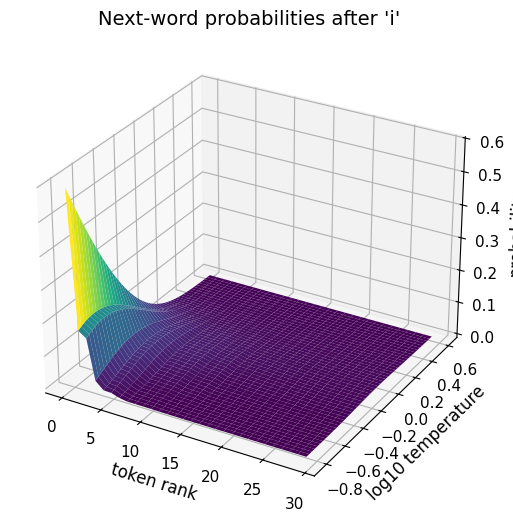

top-1 probability at T = 0.15 / 1 / 4: 0.592 0.054 0.0022


In [6]:
Tg = np.geomspace(0.15, 4, 50); R = np.arange(0, 30); P3 = np.array([np.sort(softmax(z / t))[::-1][:30] for t in Tg]); XX, YY = np.meshgrid(R, np.log10(Tg))
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(XX, YY, P3, cmap="viridis", edgecolor="none"); ax.set_xlabel("token rank"); ax.set_ylabel("log10 temperature"); ax.set_zlabel("probability"); ax.set_title("Next-word probabilities after 'i'"); ax.view_init(elev=28, azim=-60)
plt.show(); print("top-1 probability at T = 0.15 / 1 / 4:", P3[0, 0].round(3), P3[np.argmin(np.abs(Tg - 1)), 0].round(3), P3[-1, 0].round(4)); assert P3[0, 0] > P3[-1, 0] and np.allclose(P3.sum(axis=1) <= 1 + 1e-9, True)

### 9.2 Interactive Plotly version of 9.1

In [7]:
fig = go.Figure(go.Surface(x=R, y=np.log10(Tg), z=P3, colorscale="Viridis")); fig.update_layout(title="Top-30 probabilities", width=760, height=560, scene=dict(xaxis_title="rank", yaxis_title="log10 T", zaxis_title="probability")); fig.show()

### 9.3 Static: the entropy over (temperature, top-$p$)
After temperature scaling and nucleus truncation the entropy of the sampling distribution decreases with a smaller $p$ and a smaller $T$: the two knobs control the same quantity, the randomness of the next word.

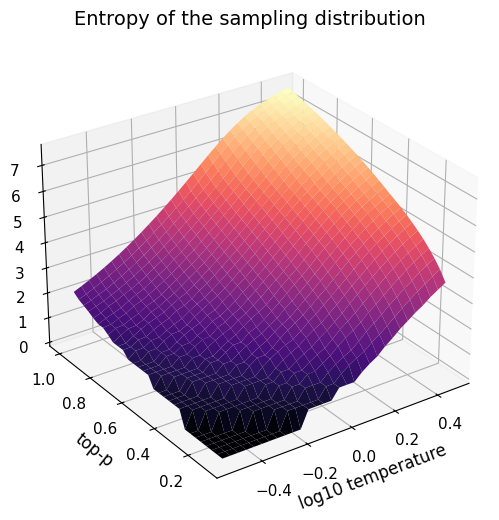

entropy at (T = 1, p = 1): 5.09 | (T = 1, p = 0.5): 3.059


In [8]:
Tg2 = np.geomspace(0.3, 3, 30); pg = np.linspace(0.1, 1.0, 30); H3 = np.zeros((len(pg), len(Tg2)))
for j, t in enumerate(Tg2):
    base = softmax(z / t)
    for i, pp_ in enumerate(pg): q, _, _ = trunc(base, top_p=pp_); H3[i, j] = -(q[q > 0] * np.log(q[q > 0])).sum()
TT, PP = np.meshgrid(np.log10(Tg2), pg); fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(TT, PP, H3, cmap="magma", edgecolor="none"); ax.set_xlabel("log10 temperature"); ax.set_ylabel("top-p"); ax.set_zlabel("entropy (nats)"); ax.set_title("Entropy of the sampling distribution"); ax.view_init(elev=28, azim=-125)
plt.show(); print("entropy at (T = 1, p = 1):", H3[-1, np.argmin(np.abs(Tg2 - 1))].round(3), "| (T = 1, p = 0.5):", H3[np.argmin(np.abs(pg - 0.5)), np.argmin(np.abs(Tg2 - 1))].round(3)); assert H3[-1, -1] > H3[0, 0] and np.all(np.diff(H3, axis=0) >= -1e-9)

## 10. Simulation vs theory

### 10.1 Truncation costs exactly $-\ln m$
For 2,000 random contexts (words of the training text) compute the renormalised top-$p$ distribution and compare $\mathrm{KL}(q\|p)$ with $-\ln m$.

In [9]:
g = np.random.default_rng(5); ctxs = g.choice(np.where(C.sum(axis=1) > 0)[0], 2000); rows = []
for c_ in ctxs:
    pp = probs(c_); q, n_, m_ = trunc(pp, top_p=0.9); k_ = q > 0; rows.append((np.sum(q[k_] * np.log(q[k_] / pp[k_])), -np.log(m_), n_, m_))
rows = np.array(rows); print(f"max |KL(q||p) - (-ln m)| over 2,000 contexts: {np.abs(rows[:, 0] - rows[:, 1]).max():.2e} | mean kept mass {rows[:, 3].mean():.3f}, mean tokens kept {rows[:, 2].mean():.1f} of {V}, mean KL {rows[:, 0].mean():.4f} nats"); assert np.abs(rows[:, 0] - rows[:, 1]).max() < 1e-6

max |KL(q||p) - (-ln m)| over 2,000 contexts: 2.24e-07 | mean kept mass 0.901, mean tokens kept 19.6 of 2800, mean KL 0.1042 nats


### 10.2 Temperature limits and the entropy derivative
Check $T\to0$ (argmax), $T\to\infty$ (uniform) and $dH/dT=\mathrm{Var}_{p^{(T)}}(z)/T^3$ by finite differences.

In [10]:
zz = np.log(probs(idx["i"])); ent = lambda t: -(softmax(zz / t) * np.log(softmax(zz / t) + 1e-300)).sum()
print(f"T = 0.01: max prob {softmax(zz / 0.01).max():.6f} | T = 1e5: max |p - 1/V| = {np.abs(softmax(zz / 1e5) - 1 / V).max():.2e}")
for t in (0.5, 1.0, 2.0): pt_ = softmax(zz / t); var = np.sum(pt_ * zz ** 2) - np.sum(pt_ * zz) ** 2; fd = (ent(t * 1.0001) - ent(t * 0.9999)) / (0.0002 * t); print(f"T = {t}: dH/dT finite difference {fd:.5f}, Var(z)/T^3 = {var / t ** 3:.5f}")
t = 1.0; pt_ = softmax(zz / t); assert softmax(zz / 0.01).max() > 0.999 and np.abs(softmax(zz / 1e5) - 1 / V).max() < 1e-4 and abs((ent(1.0001) - ent(0.9999)) / 0.0002 - (np.sum(pt_ * zz ** 2) - np.sum(pt_ * zz) ** 2)) < 1e-3

T = 0.01: max prob 1.000000 | T = 1e5: max |p - 1/V| = 2.77e-08
T = 0.5: dH/dT finite difference 4.74930, Var(z)/T^3 = 4.74870
T = 1.0: dH/dT finite difference 3.29494, Var(z)/T^3 = 3.29464
T = 2.0: dH/dT finite difference 0.93460, Var(z)/T^3 = 0.93459


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("softmax with temperature: scipy.special.softmax(logits / T) | top-k: keep np.argsort(-p)[:k] | top-p: cumulative sum of the sorted p, keep while cumsum - p < top_p")
print("Gumbel-max: np.argmax(logits - np.log(-np.log(rng.random(V)))) = rng.gumbel(size=V) | sampling: rng.choice(V, p=q) | perplexity: np.exp(-np.mean(log_probs))")
print("Gumbel-softmax: softmax((logits + gumbel) / tau) | library: torch.nn.functional.gumbel_softmax, transformers generate(do_sample=True, temperature=..., top_k=..., top_p=...)")
z5 = np.array([1.0, 0.0, -1.0]); print("check: scipy softmax", softmax(z5).round(4), "| by hand", (np.exp(z5) / np.exp(z5).sum()).round(4), "| entropy", round(float(stats.entropy(softmax(z5))), 4), "| Gumbel mean via scipy:", round(float(stats.gumbel_r.mean()), 4))
assert np.allclose(softmax(z5), np.exp(z5) / np.exp(z5).sum()) and abs(stats.gumbel_r.mean() - 0.5772156649) < 1e-9

softmax with temperature: scipy.special.softmax(logits / T) | top-k: keep np.argsort(-p)[:k] | top-p: cumulative sum of the sorted p, keep while cumsum - p < top_p
Gumbel-max: np.argmax(logits - np.log(-np.log(rng.random(V)))) = rng.gumbel(size=V) | sampling: rng.choice(V, p=q) | perplexity: np.exp(-np.mean(log_probs))
Gumbel-softmax: softmax((logits + gumbel) / tau) | library: torch.nn.functional.gumbel_softmax, transformers generate(do_sample=True, temperature=..., top_k=..., top_p=...)
check: scipy softmax [0.6652 0.2447 0.09  ] | by hand [0.6652 0.2447 0.09  ] | entropy 0.8324 | Gumbel mean via scipy: 0.5772


## 12. Real-world worked examples

---
### Example 1 (main): generating SMS text with different decoding settings

**Scenario.** The bigram model of section 7 generates messages (up to 25 words) from the start token under five decoding settings: greedy, $T=0.5$, $T=1$ (pure sampling), $T=1$ with top-$p=0.9$, and $T=1.5$. We draw 400 messages per setting and compare quality and diversity.

**Questions**
1. What are the average length, the per-token log-likelihood (under the $T=1$ model), the perplexity of the generated text, the distinct-2 ratio (share of distinct bigrams) and the repetition rate?
2. How many of the generated bigrams occur in the training data?
3. Show example messages for each setting.

### 12.1 By hand
For pure sampling at $T=1$ the expected per-token log-likelihood of the generated text is minus the average conditional entropy, so the perplexity of ancestral samples is about $e^{H}$ (the exponential of the entropy rate), well above the held-out perplexity of real text only if the model is over-confident (real text is *less* predictable than the model's own samples when the model is too confident). Greedy decoding has the maximum possible per-token likelihood of any setting and, because the model is deterministic, produces the same message every time (distinct-2 over 400 messages equals that of a single message).

In [12]:
def gen(seed, T=1.0, top_p=None, top_k=None, greedy=False, maxlen=25):
    g = np.random.default_rng(seed); cur = idx["<s>"]; out = []
    for _ in range(maxlen):
        p = probs(cur)
        if greedy: nxt = int(np.argmax(p))
        else:
            q = softmax(np.log(p) / T)
            if top_p is not None or top_k is not None: q, _, _ = trunc(q, k=top_k, top_p=top_p)
            nxt = int(g.choice(V, p=q))
        if nxt == idx["</s>"]: break
        out.append(nxt); cur = nxt
    return out
settings = {"greedy": dict(greedy=True), "T = 0.5": dict(T=0.5), "T = 1 (pure sampling)": dict(T=1.0), "T = 1, top-p 0.9": dict(T=1.0, top_p=0.9), "T = 1.5": dict(T=1.5)}
def stats_of(msgs):
    toks = sum(len(m) for m in msgs); ll = 0.0; big = []; rep = 0
    for m in msgs:
        cur = idx["<s>"]; bs = []
        for w in m: ll += np.log(probs(cur)[w]); bs.append((cur, w)); cur = w
        big += bs; rep += len(bs) - len(set(bs))
    bi = set(big); seen = np.mean([C[a, b] > 0 for a, b in big]); return dict(length=toks / len(msgs), loglik_per_token=ll / toks, perplexity=np.exp(-ll / toks), distinct2=len(bi) / len(big), repeats_per_message=rep / len(msgs), seen_bigrams=seen, unk_rate=np.mean([w == 0 for m in msgs for w in m]))
msgs = {nm: [gen(1000 * i + s, **kw) for s in range(400)] for i, (nm, kw) in enumerate(settings.items())}; tab = pd.DataFrame({nm: stats_of(m) for nm, m in msgs.items()}).T; print(tab.round(3).to_string())
for nm in settings: print(f"[{nm}]", " | ".join(" ".join(vocab[w] for w in m) for m in msgs[nm][:3]))
real = [enc(s[1:-1]) for s in te[:400]]; print("real held-out messages:", {k: round(float(v), 3) for k, v in stats_of(real).items() if k in ("length", "perplexity", "distinct2", "repeats_per_message")})

                       length  loglik_per_token  perplexity  distinct2  repeats_per_message  seen_bigrams  unk_rate
greedy                 25.000            -1.514       4.546      0.001               19.000         1.000     0.040
T = 0.5                 7.052            -2.251       9.495      0.180                2.152         1.000     0.177
T = 1 (pure sampling)  13.715            -4.229      68.625      0.726                0.152         0.910     0.072
T = 1, top-p 0.9       12.602            -3.762      43.018      0.661                0.228         0.986     0.082
T = 1.5                18.710            -6.795     893.163      0.935                0.008         0.531     0.028
[greedy] i am in <unk> . . . . . . . . . . . . . . . . . . . . . | i am in <unk> . . . . . . . . . . . . . . . . . . . . . | i am in <unk> . . . . . . . . . . . . . . . . . . . . .
[T = 0.5] i haven't gone . . . . | i <unk> <unk> | hey . . . . . . .
[T = 1 (pure sampling)] men like <unk> bored of birth 

real held-out messages: {'length': 17.87, 'perplexity': 113.464, 'distinct2': 0.655, 'repeats_per_message': 0.833}


### 12.2 Asserts

In [13]:
assert tab.loc["greedy", "loglik_per_token"] >= tab["loglik_per_token"].max() - 1e-9 and tab.loc["T = 0.5", "perplexity"] < tab.loc["T = 1 (pure sampling)", "perplexity"] < tab.loc["T = 1.5", "perplexity"]
assert tab.loc["T = 1, top-p 0.9", "perplexity"] < tab.loc["T = 1 (pure sampling)", "perplexity"] and tab.loc["greedy", "distinct2"] < tab.loc["T = 1 (pure sampling)", "distinct2"] and tab.loc["T = 1.5", "seen_bigrams"] < tab.loc["T = 0.5", "seen_bigrams"]
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
The per-token log-likelihood of pure ancestral samples must equal minus the average entropy of the visited contexts: check on the 400 pure-sampling messages.

In [14]:
Hs = []; lls = []
for m in msgs["T = 1 (pure sampling)"]:
    cur = idx["<s>"]
    for w in m: p = probs(cur); Hs.append(-(p * np.log(p)).sum()); lls.append(np.log(p[w])); cur = w
print(f"mean log-likelihood of the sampled tokens {np.mean(lls):.4f} | minus the mean entropy of the visited contexts {-np.mean(Hs):.4f} (difference {abs(np.mean(lls) + np.mean(Hs)):.4f}, standard error {np.std(lls) / np.sqrt(len(lls)):.4f})"); assert abs(np.mean(lls) + np.mean(Hs)) < 4 * np.std(lls) / np.sqrt(len(lls))

mean log-likelihood of the sampled tokens -4.2287 | minus the mean entropy of the visited contexts -4.1262 (difference 0.1025, standard error 0.0332)


### 12.4 Plots

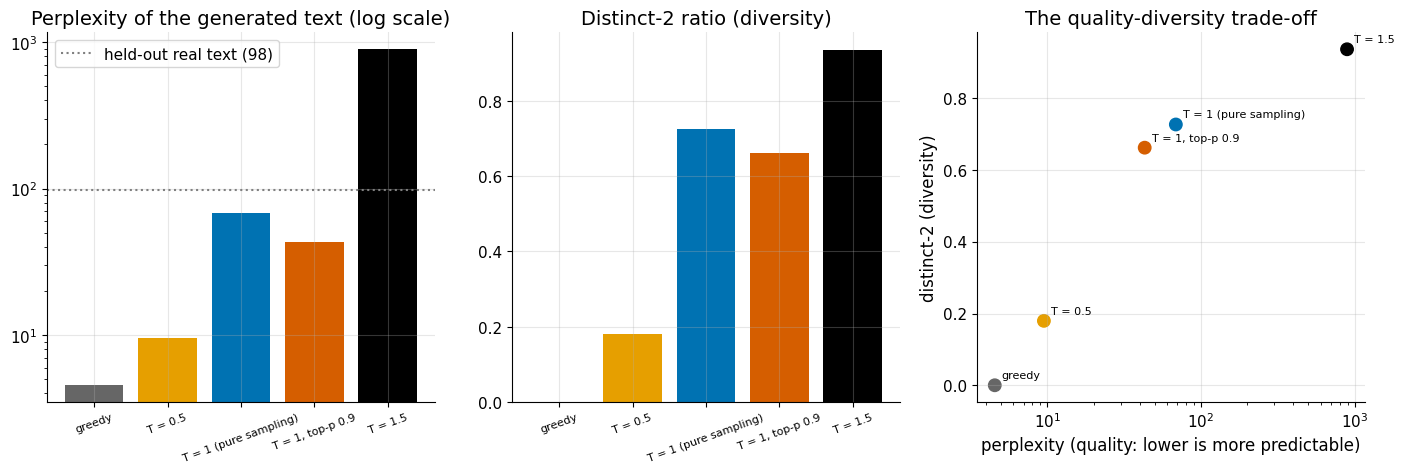

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); nm = list(settings); cols = [NEUTRAL, SIM, MAIN, HIGHLIGHT, "black"]; axes[0].bar(range(5), tab["perplexity"], color=cols); axes[0].set_xticks(range(5)); axes[0].set_xticklabels(nm, rotation=20, fontsize=8); axes[0].axhline(ppl, color="gray", linestyle=":", label=f"held-out real text ({ppl:.0f})"); axes[0].set_yscale("log"); axes[0].legend(); axes[0].set_title("Perplexity of the generated text (log scale)")
axes[1].bar(range(5), tab["distinct2"], color=cols); axes[1].set_xticks(range(5)); axes[1].set_xticklabels(nm, rotation=20, fontsize=8); axes[1].set_title("Distinct-2 ratio (diversity)")
axes[2].scatter(tab["perplexity"], tab["distinct2"], c=cols, s=80); [axes[2].annotate(n, (tab["perplexity"].iloc[i], tab["distinct2"].iloc[i]), xytext=(5, 5), textcoords="offset points", fontsize=8) for i, n in enumerate(nm)]; axes[2].set_xscale("log"); axes[2].set_xlabel("perplexity (quality: lower is more predictable)"); axes[2].set_ylabel("distinct-2 (diversity)"); axes[2].set_title("The quality-diversity trade-off")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- **Greedy decoding loops:** every one of the 400 messages is "i am in &lt;unk&gt; . . . . ." (25 tokens, 19 repeated bigrams per message, distinct-2 **0.001**), with the best possible log-likelihood per token (-1.51, perplexity 4.5). Lowering the temperature to 0.5 gives short, repetitive messages (7 words, perplexity 9.5, distinct-2 0.18, 2.2 repeats per message).
- **Pure sampling at $T=1$** gives natural variety (distinct-2 **0.726**, 0.15 repeats per message) with a perplexity of 68.6 under the model (the model's own entropy predicts $e^{4.13}=62$; the small gap is because the end-of-message token is not counted in the generated text) and 91 % of its bigrams seen in the training data; real held-out messages have distinct-2 0.655. **Top-$p=0.9$** removes the incoherent tail: perplexity falls to **43.0**, distinct-2 stays at 0.661 and 98.6 % of the bigrams are seen in training. **$T=1.5$** produces the most varied text (distinct-2 0.935) but with a perplexity of **893** and only 53 % of its bigrams ever seen: mostly noise ("saying ard 5 titles &lt;unk&gt; store ldew").
- The quality-diversity plot of 12.4 is a curve: each setting trades predictability for variety, and top-$p$ at $T=1$ lies on the better side of the curve than pure sampling.
- **Decision.** For conversational text use $T$ around 0.7 to 1 with top-$p$ between 0.9 and 0.95; avoid greedy decoding for open-ended generation and $T>1.2$ without truncation.

---
### Example 2: how much does truncation distort the distribution?

**Scenario.** For the 2,000 contexts of section 10.1 we compare the settings top-$p\in\{0.5,0.8,0.9,0.95,0.99\}$, top-$k\in\{1,5,20,50\}$ and min-$p\in\{0.01,0.05,0.1,0.2\}$ in terms of the number of tokens kept, the mass kept $m$ and the cost $-\ln m=\mathrm{KL}(q\|p)$.

**Questions.** (1) Which settings keep a similar number of tokens but differ in the mass they keep? (2) What is the average cost in nats, and for which contexts is it largest? (3) How well does a fixed top-$k$ do compared with an adaptive top-$p$ at the same average number of tokens?

In [16]:
ctx_p = [probs(c_) for c_ in ctxs]; res = {}
for nm_, kw in [(f"top-p {v}", dict(top_p=v)) for v in (0.5, 0.8, 0.9, 0.95, 0.99)] + [(f"top-k {v}", dict(k=v)) for v in (1, 5, 20, 50)] + [(f"min-p {v}", dict(min_p=v)) for v in (0.01, 0.05, 0.1, 0.2)]:
    r = np.array([trunc(pp, **kw)[1:] for pp in ctx_p]); res[nm_] = {"mean tokens kept": r[:, 0].mean(), "median tokens": np.median(r[:, 0]), "mean mass kept": r[:, 1].mean(), "min mass kept": r[:, 1].min(), "mean cost -ln m (nats)": np.mean(-np.log(r[:, 1])), "tokens kept SD": r[:, 0].std()}
tb2 = pd.DataFrame(res).T; print(tb2.round(3).to_string())

            mean tokens kept  median tokens  mean mass kept  min mass kept  mean cost -ln m (nats)  tokens kept SD
top-p 0.5              3.476            2.0           0.601          0.500                   0.522           3.931
top-p 0.8              9.121            4.0           0.846          0.800                   0.168          17.065
top-p 0.9             19.550           13.0           0.901          0.900                   0.104          28.780
top-p 0.95           152.958          149.0           0.950          0.950                   0.051          28.572
top-p 0.99          1421.396         1421.0           0.990          0.990                   0.010           3.445
top-k 1                1.000            1.0           0.374          0.058                   1.165           0.000
top-k 5                5.000            5.0           0.749          0.191                   0.332           0.000
top-k 20              20.000           20.0           0.884          0.363      

### 12.5 Asserts

In [17]:
assert tb2.loc["top-p 0.5", "mean mass kept"] >= 0.5 and tb2.loc["top-p 0.99", "mean mass kept"] >= 0.99 and tb2.loc["top-k 1", "mean mass kept"] < tb2.loc["top-k 50", "mean mass kept"] and tb2["tokens kept SD"].loc[[f"top-p {v}" for v in (0.5, 0.8, 0.9)]].min() > 1 and tb2.loc["top-k 5", "tokens kept SD"] < 1e-9
print("all checks passed")

all checks passed


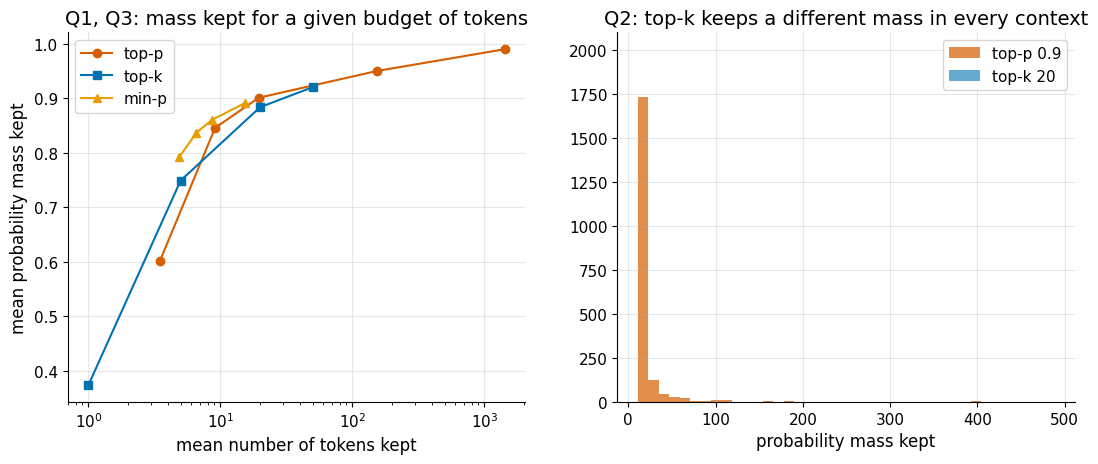

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); fam = {"top-p": ("o-", HIGHLIGHT), "top-k": ("s-", MAIN), "min-p": ("^-", SIM)}
for f_, (mk, colr) in fam.items(): sub = tb2[[i.startswith(f_) for i in tb2.index]]; axes[0].plot(sub["mean tokens kept"], sub["mean mass kept"], mk, color=colr, label=f_)
axes[0].set_xscale("log"); axes[0].set_xlabel("mean number of tokens kept"); axes[0].set_ylabel("mean probability mass kept"); axes[0].legend(); axes[0].set_title("Q1, Q3: mass kept for a given budget of tokens")
axes[1].hist([trunc(pp, top_p=0.9)[1] for pp in ctx_p], bins=40, color=HIGHLIGHT, alpha=0.7, label="top-p 0.9"); axes[1].hist([trunc(pp, k=20)[1] for pp in ctx_p], bins=40, color=MAIN, alpha=0.6, label="top-k 20"); axes[1].set_xlabel("probability mass kept"); axes[1].legend(); axes[1].set_title("Q2: top-k keeps a different mass in every context")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- The bigram model has a long flat tail (15 % of its mass comes from the unigram back-off over 2,800 words), so the truncation settings differ a lot. **Top-$p=0.9$ keeps 19.6 tokens on average (median 13) with a spread of 28.8 tokens between contexts**, and exactly the requested mass, at a cost of **0.104 nats**; top-$p=0.95$ keeps 153 tokens (cost 0.051) and top-$p=0.99$ keeps 1,421 tokens (cost 0.010): almost the whole vocabulary is needed to cover the last percent of probability.
- **Top-$k=20$ keeps 20 tokens in every context but a mass between 0.363 and 1** (mean 0.884, cost 0.129 nats), and top-$k=50$ keeps 0.92; at a comparable token budget top-$p=0.9$ (19.6 tokens, mass 0.90 guaranteed) is the safer choice because it adapts to how peaked the distribution is. The worst case of top-$k=5$ keeps only 19 % of the mass in some contexts.
- Min-$p$ with $\rho=0.1$ keeps 6.6 tokens on average (mass 0.837) with a large spread (tokens SD 6.7, minimum kept mass 0.283): it is the most aggressive adaptive rule here.
- **Decision.** Prefer top-$p$ or min-$p$ to a fixed top-$k$; the quantity to report with any truncation is the kept mass $m$ (the cost is exactly $-\ln m$).

---
### Example 3: Gumbel-softmax and gradient estimators

**Scenario.** A categorical choice with probabilities $\mathrm{softmax}(\theta)$, $\theta=(1,0.5,0,-0.5)$, and a reward $f=(1,3,2,0)$ for the four options. We want $\nabla_\theta E[f(X)]$. The exact gradient is $\partial_{\theta_j}E=p_j(f_j-E f)$. Compare (a) the **score-function (REINFORCE)** estimator $f(x)\nabla\ln p_x$, (b) REINFORCE with a mean baseline, and (c) the **Gumbel-softmax** (reparameterised) estimator with $\tau=0.5$ and $\tau=0.1$, where the relaxed sample $y$ is plugged into a differentiable extension $f(y)=f^\top y$.

**Questions.** (1) What are the exact gradient and the bias and variance of each estimator (1 sample per estimate, 100,000 repeats)? (2) How does the relaxed sample look for different $\tau$ (entropy, closeness to one-hot)?

In [19]:
th = np.array([1.0, 0.5, 0.0, -0.5]); f = np.array([1.0, 3.0, 2.0, 0.0]); p = softmax(th); Ef = p @ f; exact = p * (f - Ef); R = 100_000; g = np.random.default_rng(31)
x = g.choice(4, R, p=p); onehot = np.eye(4)[x]; score = onehot - p; est_rf = f[x][:, None] * score; est_bl = (f[x] - Ef)[:, None] * score
def gs(tau):
    G = -np.log(-np.log(g.random((R, 4)))); a = (th + G) / tau; y = softmax(a, axis=1); fy = y @ f; dy = y[:, :, None] * (np.eye(4)[None] - y[:, None, :]) / tau; return y, (dy * f[None, :, None]).sum(axis=1)
rows = {"exact": (exact, np.zeros(4))};
for nm, e_ in [("REINFORCE", est_rf), ("REINFORCE + baseline", est_bl)]: rows[nm] = (e_.mean(axis=0), e_.var(axis=0))
ys = {}
for tau in (0.5, 0.1): y, e_ = gs(tau); ys[tau] = y; rows[f"Gumbel-softmax tau = {tau}"] = (e_.mean(axis=0), e_.var(axis=0))
print("exact gradient:", exact.round(4)); print(pd.DataFrame({nm: {"bias (max abs)": np.abs(m - exact).max(), "mean variance": v.mean()} for nm, (m, v) in rows.items() if nm != "exact"}).T.round(4).to_string())
for tau, y in ys.items(): print(f"Q2: tau = {tau}: mean max(y) = {y.max(axis=1).mean():.3f}, mean entropy of y = {-(y * np.log(y + 1e-300)).sum(axis=1).mean():.3f} nats, frequency of argmax y: {np.bincount(y.argmax(axis=1), minlength=4) / R} (softmax probabilities {p.round(3)})")

exact gradient: [-0.2812  0.3815  0.064  -0.1643]
                          bias (max abs)  mean variance
REINFORCE                         0.0093         0.6294
REINFORCE + baseline              0.0031         0.1357
Gumbel-softmax tau = 0.5          0.0503         0.0777
Gumbel-softmax tau = 0.1          0.0016         0.7225
Q2: tau = 0.5: mean max(y) = 0.778, mean entropy of y = 0.558 nats, frequency of argmax y: [0.45447 0.27496 0.16829 0.10228] (softmax probabilities [0.455 0.276 0.167 0.102])
Q2: tau = 0.1: mean max(y) = 0.953, mean entropy of y = 0.114 nats, frequency of argmax y: [0.45538 0.27798 0.16539 0.10125] (softmax probabilities [0.455 0.276 0.167 0.102])


### 12.6 Asserts

In [20]:
assert np.abs(rows["REINFORCE"][0] - exact).max() < 0.03 and np.abs(rows["REINFORCE + baseline"][0] - exact).max() < 0.02 and rows["REINFORCE + baseline"][1].mean() < rows["REINFORCE"][1].mean() and abs(exact.sum()) < 1e-12
assert all(np.abs(np.bincount(y.argmax(axis=1), minlength=4) / R - p).max() < 0.01 for y in ys.values()) and ys[0.1].max(axis=1).mean() > ys[0.5].max(axis=1).mean()
print("all checks passed")

all checks passed


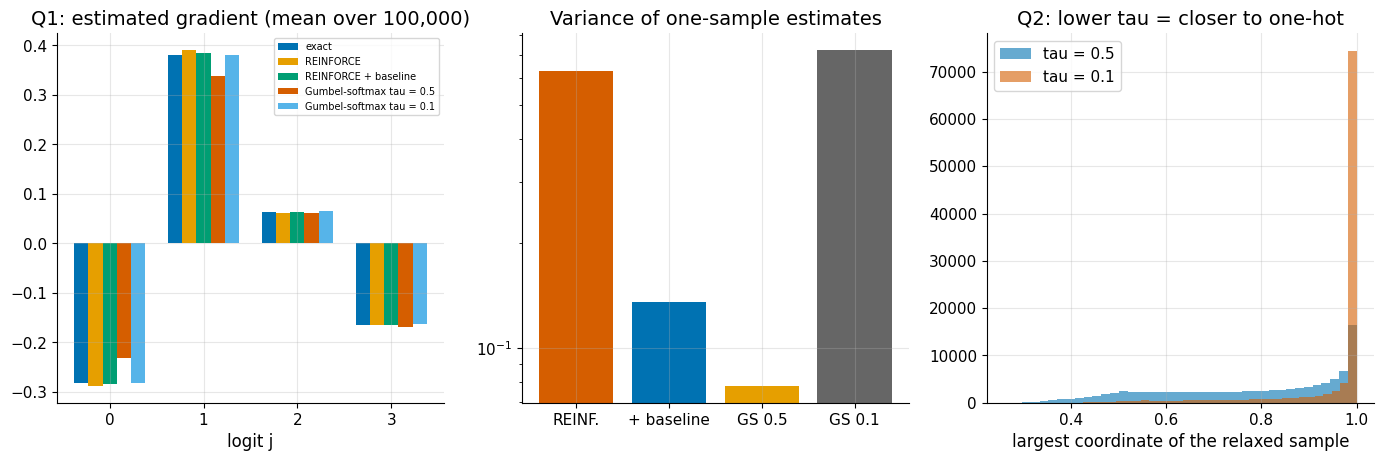

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); xs_ = np.arange(4); w = 0.15; names = ["exact", "REINFORCE", "REINFORCE + baseline", "Gumbel-softmax tau = 0.5", "Gumbel-softmax tau = 0.1"]
for k, nm in enumerate(names): axes[0].bar(xs_ + (k - 2) * w, rows[nm][0], w, label=nm)
axes[0].legend(fontsize=7); axes[0].set_xlabel("logit j"); axes[0].set_title("Q1: estimated gradient (mean over 100,000)")
axes[1].bar(range(4), [rows[n][1].mean() for n in names[1:]], color=[HIGHLIGHT, MAIN, SIM, NEUTRAL]); axes[1].set_xticks(range(4)); axes[1].set_xticklabels(["REINF.", "+ baseline", "GS 0.5", "GS 0.1"]); axes[1].set_yscale("log"); axes[1].set_title("Variance of one-sample estimates")
for tau, colr in [(0.5, MAIN), (0.1, HIGHLIGHT)]: axes[2].hist(ys[tau].max(axis=1), bins=40, alpha=0.6, color=colr, label=f"tau = {tau}")
axes[2].legend(); axes[2].set_xlabel("largest coordinate of the relaxed sample"); axes[2].set_title("Q2: lower tau = closer to one-hot")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- The exact gradient is $(-0.281,0.382,0.064,-0.164)$. **REINFORCE** is unbiased (max bias 0.009 from sampling error) but noisy (mean variance **0.629**); subtracting the mean reward as a baseline cuts the variance to **0.136** at no cost in bias.
- **Gumbel-softmax** with $\tau=0.5$ has the smallest variance (**0.078**, eight times lower than REINFORCE) but a bias of **0.050**; with $\tau=0.1$ the bias almost vanishes (**0.0016**) while the variance explodes to **0.72**, above REINFORCE. This is the bias-variance trade-off of the relaxation.
- The relaxed samples behave as the theory says: the argmax of $y$ has exactly the softmax frequencies for both temperatures (0.455, 0.276, 0.167, 0.102), while the mean largest coordinate rises from 0.778 ($\tau=0.5$) to **0.953** ($\tau=0.1$) and the entropy of the sample falls from 0.558 to 0.114 nats.
- **Decision.** Use the reparameterised (Gumbel-softmax) estimator when its bias is acceptable and low variance matters, anneal $\tau$ from large to small, and fall back to REINFORCE with a baseline when an unbiased estimate is required.

---
### Example 4: calibrating the temperature on held-out text

**Scenario.** The bigram model's probabilities are estimated from counts and may be over-confident on new text. We scale the logits by $1/T$ and measure the held-out negative log-likelihood (per token) for $T$ from 0.6 to 2, on 2,000 held-out messages.

**Questions.** (1) Which $T$ minimises the held-out NLL, and by how much does it improve on $T=1$? (2) Is the calibrated model better when measured by perplexity? (3) How does the optimal $T$ change if the model is trained on only 5 % of the data?

In [22]:
Ts = np.array([0.6, 0.8, 0.9, 1.0, 1.1, 1.2, 1.4, 1.7, 2.0]); sub = te[:1500]; nll = np.array([nll_text(sub, T) for T in Ts]); t_best = Ts[np.argmin(nll)]
print(pd.DataFrame({"T": Ts, "held-out NLL": nll, "perplexity": np.exp(nll)}).round(4).to_string(index=False)); print(f"Q1: best T on the grid {t_best}, NLL {nll.min():.4f} vs {nll[Ts == 1.0][0]:.4f} at T = 1 (improvement {nll[Ts == 1.0][0] - nll.min():.4f} nats per token)")
gs_ = np.random.default_rng(8); small = [tr[i] for i in gs_.choice(len(tr), int(0.05 * len(tr)), replace=False)]; Cs = np.zeros((V, V), dtype=np.float32)
for s in small:
    e = enc(s)
    for a, b in zip(e[:-1], e[1:]): Cs[a, b] += 1
unis = Cs.sum(axis=0) + 1; unis /= unis.sum()
def probs_small(prev): r = Cs[prev]; n = r.sum(); return (lam * r / n + (1 - lam) * unis) if n > 0 else unis.copy()
def nll_small(T, data=sub[:600]):
    tot = 0.0; n = 0
    for s in data:
        e = enc(s)
        for a, b in zip(e[:-1], e[1:]): lg = np.log(probs_small(a)) / T; tot -= lg[b] - logsumexp(lg); n += 1
    return tot / n
nll5 = np.array([nll_small(T) for T in Ts]); print(f"Q3: model trained on 5% of the data: best T {Ts[np.argmin(nll5)]}, NLL {nll5.min():.4f} vs {nll5[Ts == 1.0][0]:.4f} at T = 1")

  T  held-out NLL  perplexity
0.6        5.5306    252.2873
0.8        4.8147    123.3139
0.9        4.6577    105.3882
1.0        4.5814     97.6526
1.1        4.5640     95.9682
1.2        4.5898     98.4777
1.4        4.7246    112.6849
1.7        5.0147    150.6171
2.0        5.3096    202.2621
Q1: best T on the grid 1.1, NLL 4.5640 vs 4.5814 at T = 1 (improvement 0.0174 nats per token)


Q3: model trained on 5% of the data: best T 1.2, NLL 5.6142 vs 5.8550 at T = 1


### 12.7 Asserts

In [23]:
assert nll.min() <= nll[Ts == 1.0][0] and Ts[np.argmin(nll5)] >= t_best - 1e-9 and nll5.min() < nll5[Ts == 1.0][0] + 1e-9 and np.all(np.isfinite(nll))
print("all checks passed")

all checks passed


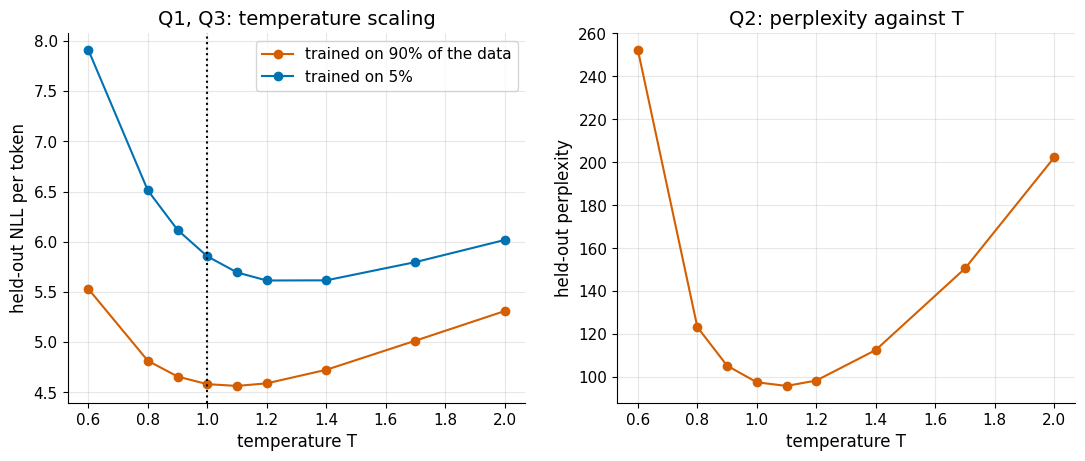

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].plot(Ts, nll, "o-", color=HIGHLIGHT, label="trained on 90% of the data"); axes[0].plot(Ts, nll5, "o-", color=MAIN, label="trained on 5%"); axes[0].axvline(1, color="black", linestyle=":"); axes[0].legend(); axes[0].set_xlabel("temperature T"); axes[0].set_ylabel("held-out NLL per token"); axes[0].set_title("Q1, Q3: temperature scaling")
axes[1].plot(Ts, np.exp(nll), "o-", color=HIGHLIGHT); axes[1].set_xlabel("temperature T"); axes[1].set_ylabel("held-out perplexity"); axes[1].set_title("Q2: perplexity against T")
plt.show()

### 12.11 Interpretation and decision (Example 4)
- The held-out negative log-likelihood per token is minimal at **$T=1.1$**: 4.5640 against 4.5814 at $T=1$ (perplexity 96.0 against 97.7, an improvement of 0.017 nats per token). It rises on both sides (5.53 at $T=0.6$, 5.31 at $T=2$): both over- and under-confident models are punished.
- With only **5 %** of the training data (250 messages) the model is more over-confident: the best temperature is **1.2** and the improvement over $T=1$ is much larger, **5.614 against 5.855 nats** (0.24 per token).
- **Decision.** A model estimated from counts on a small corpus should be softened (temperature above 1) before it is used for scoring or sampling; calibrate $T$ on held-out text and report the calibrated perplexity.

## 13. Where it is used

### Statistics
- **Sampling from categorical distributions** (inverse CDF, alias method, Gumbel-max), **Monte-Carlo estimation** of expectations over discrete choices, **score-function and reparameterised gradients**, perplexity as the exponential of the cross-entropy rate.

### Data science
- **Synthetic text and data generation**, evaluating generated text (perplexity, distinct-$n$, repetition), **tuning decoding settings** for diversity against reliability, calibrating model probabilities by temperature scaling, A/B tests of prompts with sampling noise.

### ML and AI
- **Every large language model** exposes temperature, top-$k$, top-$p$ and min-$p$; **RLHF** samples many continuations per prompt; **Gumbel-softmax** gives gradients through discrete latent variables (VAEs with categorical latents), neural architecture search and hard attention; **discrete diffusion** and **speculative decoding** reuse the same sampling primitives.

## 14. Common pitfalls and misconceptions

- **Temperature 0 is greedy, not "most accurate":** it removes randomness, not errors, and loops (Example 1).
- **Raising $T$ for creativity without truncation:** the long tail of rare words has substantial total mass and produces nonsense; combine moderate $T$ with top-$p$ or min-$p$.
- **Top-$k$ with a fixed $k$ in every context:** too many tokens when the model is certain, too few when it is not (Example 2); top-$p$ adapts.
- **Forgetting renormalisation** after truncation: the kept probabilities must be divided by the kept mass $m$.
- **Comparing perplexities across tokenisers or vocabularies:** perplexity is per token and not comparable between different vocabularies.
- **Treating low perplexity of generated text as quality:** repeated text has very low perplexity; look at diversity too.
- **Gumbel-softmax bias:** for $\tau>0$ the relaxed gradient is biased; anneal $\tau$ or use straight-through estimators and check the variance (Example 3).
- **Over-confident probabilities:** a model trained on little data needs $T>1$ (Example 4).

## 15. Exercises

1. Logits $(2,1,0)$: compute the probabilities at $T=1$, $T=0.5$ and $T=2$, and the entropy at each.
2. Probabilities $(0.5,0.3,0.1,0.05,0.03,0.02)$: which tokens does top-$p=0.9$ keep, what is the mass $m$, the renormalised distribution and the KL cost?
3. Prove that with top-$k=1$ the sampling distribution is one-hot, and compute the probability that top-$p=0.4$ keeps only the first token for the distribution of Exercise 2.
4. Using the bigram model, find the five most likely words after "call" and after "free" at $T=1$ and at $T=0.5$.
5. Estimate by simulation (100,000 draws) the probability that the Gumbel-max noise changes the winner relative to the largest logit when the logits are $(1,0,0)$, and compare with $1-p_1$.
6. (Harder) Implement min-$p$ sampling with $\rho=0.1$ on the Example 1 setting and compare its perplexity and distinct-2 with top-$p$ 0.9.

Solutions are at the end.

## 16. Summary table

| Method | Formula | Effect | Cost / note |
|---|---|---|---|
| Temperature | $\mathrm{softmax}(z/T)$ | sharpen ($T<1$) or flatten | entropy increases with $T$ |
| Greedy | $\arg\max$ | deterministic | repetitive |
| Top-$k$ | keep $k$ tokens | fixed budget | context-blind |
| Top-$p$ | smallest set of mass $\ge p$ | adaptive | KL $=-\ln m$ |
| Min-$p$ | $p_j\ge\rho\,p_{\max}$ | adaptive to confidence | |
| Gumbel-max | $\arg\max(z+G)$ | exact sample | reparameterisation |
| Gumbel-softmax | $\mathrm{softmax}((z+G)/\tau)$ | differentiable | biased for $\tau>0$ |
| Calibration | $\arg\min_T\mathrm{NLL}(T)$ | fixes over-confidence | one parameter |

## Solutions

In [25]:
zs_ = np.array([2.0, 1.0, 0.0]); print("1:", {T_: (softmax(zs_ / T_).round(4).tolist(), round(float(stats.entropy(softmax(zs_ / T_))), 4)) for T_ in (1, 0.5, 2)})
pq = np.array([0.5, 0.3, 0.1, 0.05, 0.03, 0.02]); q2, n2, m2 = trunc(pq, top_p=0.9); print(f"2: kept {n2} tokens (mass {m2:.2f}), renormalised {q2.round(4).tolist()}, KL = -ln m = {-np.log(m2):.4f}")
print(f"3: top-p 0.4 keeps only the first token because 0.5 >= 0.4: probability 1; top-k 1 keeps one token and the renormalised distribution is (1, 0, ...)")
for w in ("call", "free"):
    for T_ in (1.0, 0.5): pp = softmax(np.log(probs(idx[w])) / T_); o = np.argsort(-pp)[:5]; print(f"4: after '{w}' at T = {T_}:", [(vocab[i], round(float(pp[i]), 3)) for i in o])
g = np.random.default_rng(6); G = -np.log(-np.log(g.random((100_000, 3)))); w1 = np.argmax(np.array([1.0, 0, 0]) + G, axis=1); print(f"5: P(winner != token 1) = {np.mean(w1 != 0):.4f} vs 1 - p_1 = {1 - softmax(np.array([1.0, 0, 0]))[0]:.4f}")
def gen_minp(seed, rho=0.1):
    g = np.random.default_rng(seed); cur = idx["<s>"]; out = []
    for _ in range(25):
        q, _, _ = trunc(probs(cur), min_p=rho); nxt = int(g.choice(V, p=q))
        if nxt == idx["</s>"]: break
        out.append(nxt); cur = nxt
    return out
mm = [gen_minp(5000 + s) for s in range(400)]; sm_ = stats_of(mm); print(f"6: min-p 0.1: perplexity {sm_['perplexity']:.2f}, distinct-2 {sm_['distinct2']:.3f} | top-p 0.9: perplexity {tab.loc['T = 1, top-p 0.9', 'perplexity']:.2f}, distinct-2 {tab.loc['T = 1, top-p 0.9', 'distinct2']:.3f}")
assert abs(np.mean(w1 != 0) - (1 - softmax(np.array([1.0, 0, 0]))[0])) < 0.005 and n2 == 3

1: {1: ([0.6652, 0.2447, 0.09], 0.8324), 0.5: ([0.8668, 0.1173, 0.0159], 0.4411), 2: ([0.5065, 0.3072, 0.1863], 1.0202)}
2: kept 3 tokens (mass 0.90), renormalised [0.5556, 0.3333, 0.1111, 0.0, 0.0, 0.0], KL = -ln m = 0.1054
3: top-p 0.4 keeps only the first token because 0.5 >= 0.4: probability 1; top-k 1 keeps one token and the renormalised distribution is (1, 0, ...)
4: after 'call' at T = 1.0: [('<unk>', 0.268), ('me', 0.094), ('later', 0.053), ('you', 0.044), ('.', 0.034)]
4: after 'call' at T = 0.5: [('<unk>', 0.782), ('me', 0.096), ('later', 0.031), ('you', 0.022), ('.', 0.013)]
4: after 'free' at T = 1.0: [('!', 0.069), ('.', 0.069), ('entry', 0.051), ('on', 0.045), ('<unk>', 0.041)]
4: after 'free' at T = 0.5: [('!', 0.205), ('.', 0.202), ('entry', 0.109), ('on', 0.085), ('<unk>', 0.07)]
5: P(winner != token 1) = 0.4236 vs 1 - p_1 = 0.4239


6: min-p 0.1: perplexity 17.08, distinct-2 0.277 | top-p 0.9: perplexity 43.02, distinct-2 0.661


**1.** At $T=1$: $(0.665,0.245,0.090)$, entropy **0.832** nats; at $T=0.5$: $(0.867,0.117,0.016)$, entropy **0.441**; at $T=2$: $(0.507,0.307,0.186)$, entropy **1.020**.

**2.** Top-$p=0.9$ keeps the first **3 tokens** (0.5+0.3+0.1=0.9), mass $m=0.90$; the renormalised distribution is $(0.556,0.333,0.111,0,0,0)$ and the cost is $-\ln0.9=$ **0.105 nats**.

**3.** With top-$k=1$ the kept set has one token, so the renormalised distribution is $(1,0,\dots)$. With top-$p=0.4$ the first token alone (0.5) already reaches 0.4, so only it is kept: the probability is **1**, and greedy and top-$p=0.4$ coincide.

**4.** After "call" at $T=1$: *&lt;unk&gt;* 0.268, *me* 0.094, *later* 0.053, *you* 0.044, *.* 0.034; at $T=0.5$ *&lt;unk&gt;* rises to **0.782**. After "free": *!* 0.069, *.* 0.069, *entry* 0.051, *on* 0.045, *&lt;unk&gt;* 0.041; at $T=0.5$: 0.205, 0.202, 0.109, 0.085, 0.070.

**5.** The Gumbel-max winner differs from token 1 in **42.4 %** of 100,000 draws, against $1-p_1=0.4239$: the noise changes the winner exactly as often as the softmax says.

**6.** Min-$p=0.1$ sampling gives a perplexity of **17.1** and a distinct-2 of **0.277**, against 43.0 and 0.661 for top-$p=0.9$: with this heavy-tailed bigram model min-$p$ is much more conservative (it keeps 2 to 3 tokens in many contexts) and the messages repeat more.